In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../data/raw/student_academic_data.csv")

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df.head()

Dataset loaded successfully!
Rows: 5000
Columns: 11


,student_id,attendance,previous_cgpa,internal_marks,assignment_score,study_hours,backlogs,previous_failures,participation_score,final_score,risk_level
0,100001,81.66,6.89,70.64,85.00,0.52,0,0,67.15,54.15,MEDIUM
1,100002,65.52,6.84,81.49,85.46,5.10,0,0,86.34,67.70,LOW
2,100003,87.01,6.36,45.92,82.50,3.40,3,0,60.13,51.58,MEDIUM
3,100004,89.29,7.71,63.72,78.16,2.42,1,0,94.44,62.48,LOW
4,100005,54.59,7.48,80.44,77.78,3.05,1,1,79.59,56.11,MEDIUM


In [2]:
# Data Quality Check

print("=== DATA TYPES ===")
print(df.dtypes)

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== TOTAL MISSING VALUES ===")
print(df.isnull().sum().sum())

print("\n=== DUPLICATE ROWS ===")
print(df.duplicated().sum())

=== DATA TYPES ===
student_id               int64
attendance             float64
previous_cgpa          float64
internal_marks         float64
assignment_score       float64
study_hours            float64
backlogs                 int64
previous_failures        int64
participation_score    float64
final_score            float64
risk_level                 str
dtype: object

=== MISSING VALUES ===
student_id             0
attendance             0
previous_cgpa          0
internal_marks         0
assignment_score       0
study_hours            0
backlogs               0
previous_failures      0
participation_score    0
final_score            0
risk_level             0
dtype: int64

=== TOTAL MISSING VALUES ===
0

=== DUPLICATE ROWS ===
0


In [3]:
# Statistical and Range Validation

print("=== DATASET SUMMARY ===")
display(df.describe().T)

print("\n=== RISK LEVEL DISTRIBUTION ===")
print(df["risk_level"].value_counts())

print("\n=== RISK LEVEL PERCENTAGE ===")
print(
    (df["risk_level"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n=== UNIQUE VALUES ===")
print(df.nunique())

=== DATASET SUMMARY ===


,count,mean,std,min,25%,50%,75%,max
student_id,5000.0,102500.500000,1443.520003,100001.0,101250.7500,102500.500,103750.2500,105000.0
attendance,5000.0,77.601730,11.627606,40.0,69.7000,77.950,85.5725,100.0
previous_cgpa,5000.0,7.196648,1.197300,4.0,6.4100,7.180,8.0100,10.0
internal_marks,5000.0,67.781714,14.758671,20.0,57.7900,67.520,77.9350,100.0
assignment_score,5000.0,72.581344,13.829900,20.2,63.0375,72.655,82.2300,100.0
study_hours,5000.0,3.571474,1.715196,0.5,2.3500,3.540,4.7125,9.9
backlogs,5000.0,0.806400,0.898822,0.0,0.0000,1.000,1.0000,6.0
previous_failures,5000.0,0.525400,0.720735,0.0,0.0000,0.000,1.0000,4.0
participation_score,5000.0,67.574390,16.353090,10.0,56.6275,67.790,78.9725,100.0
final_score,5000.0,56.588580,11.248474,0.0,49.1475,56.460,64.2500,100.0



=== RISK LEVEL DISTRIBUTION ===
risk_level
LOW       2500
MEDIUM    1750
HIGH       750
Name: count, dtype: int64

=== RISK LEVEL PERCENTAGE ===
risk_level
LOW       50.0
MEDIUM    35.0
HIGH      15.0
Name: proportion, dtype: float64

=== UNIQUE VALUES ===
student_id             5000
attendance             2897
previous_cgpa           562
internal_marks         3216
assignment_score       3124
study_hours             736
backlogs                  7
previous_failures         5
participation_score    3279
final_score            2918
risk_level                3
dtype: int64


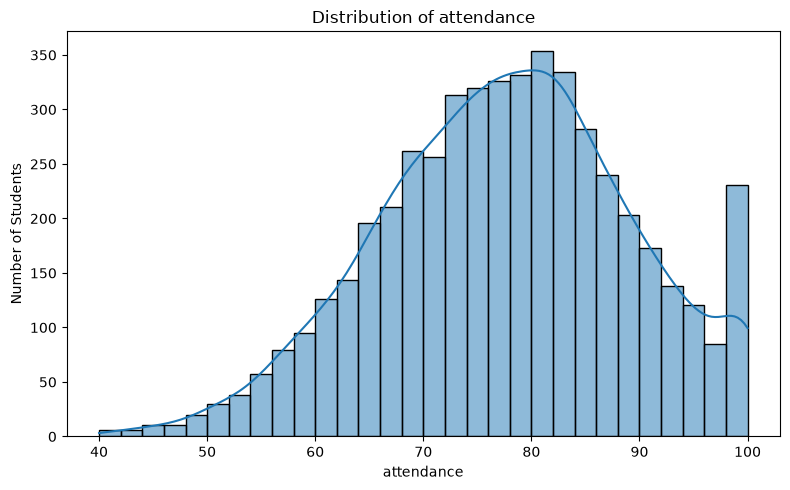

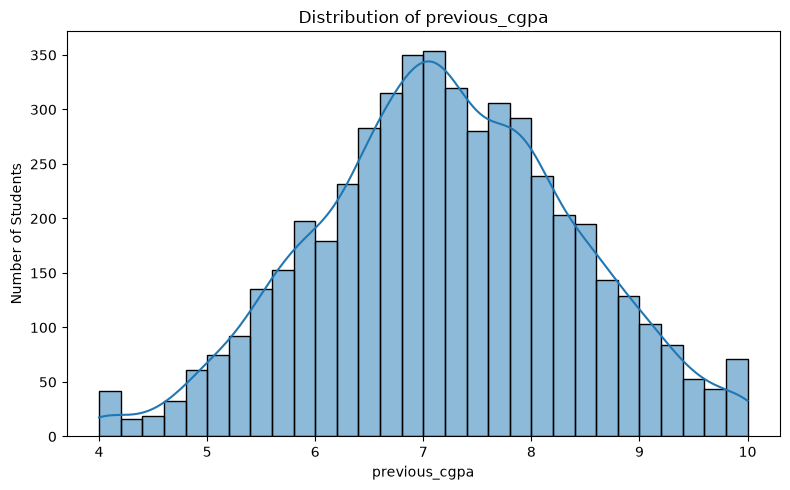

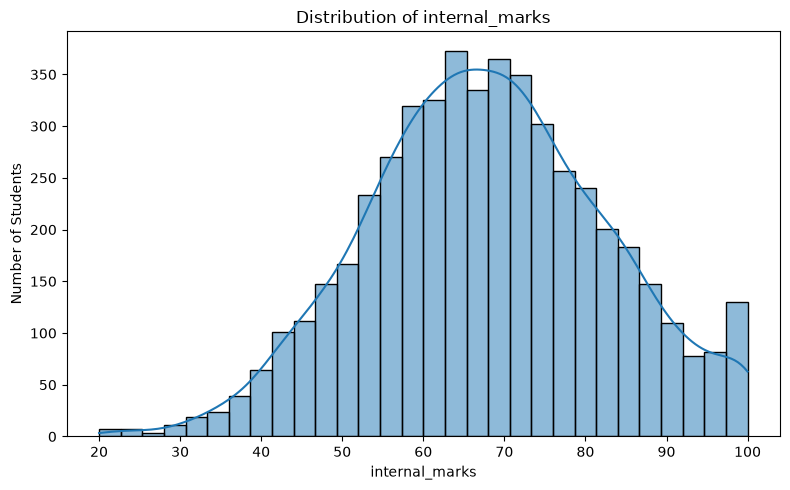

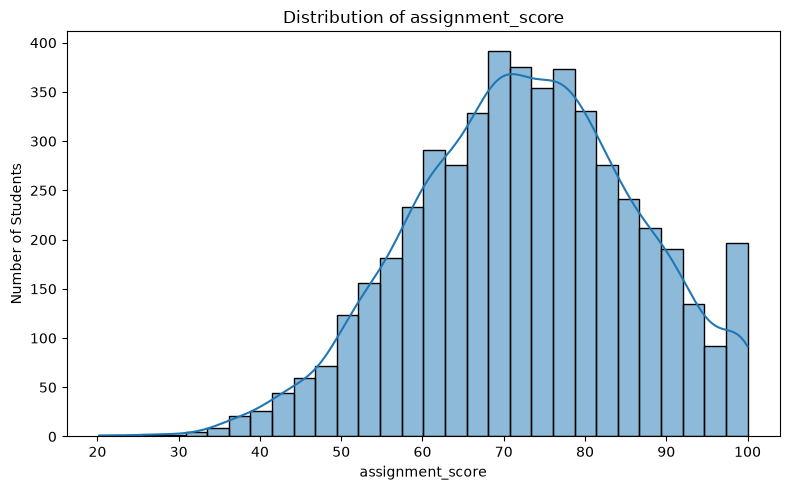

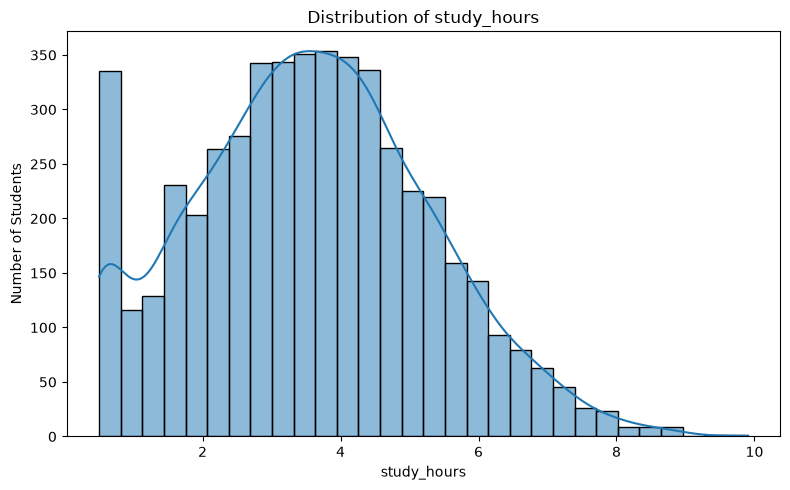

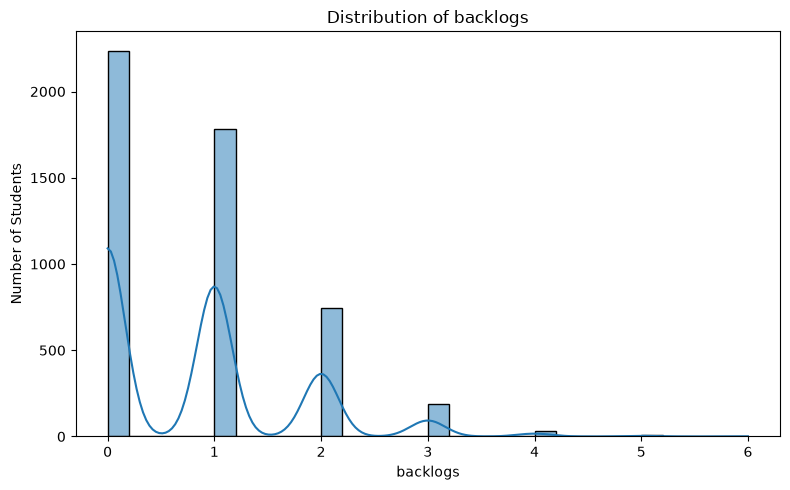

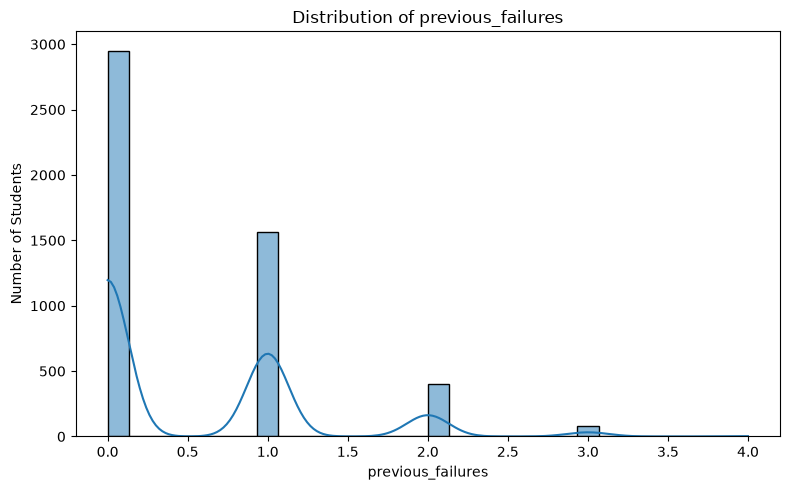

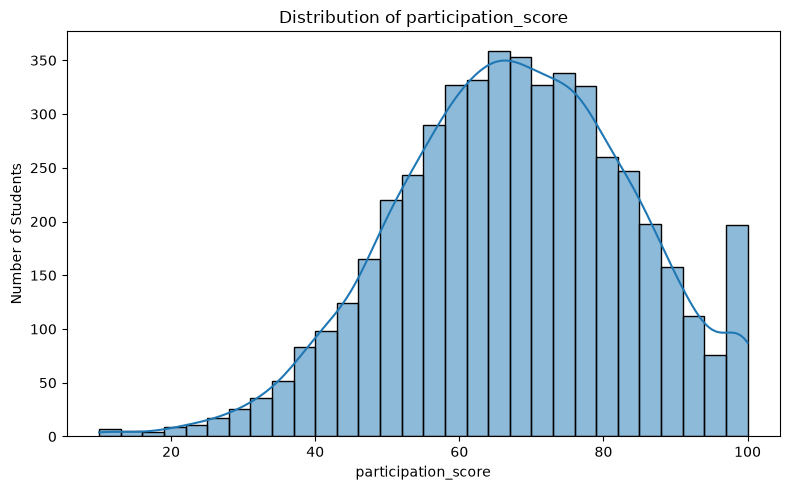

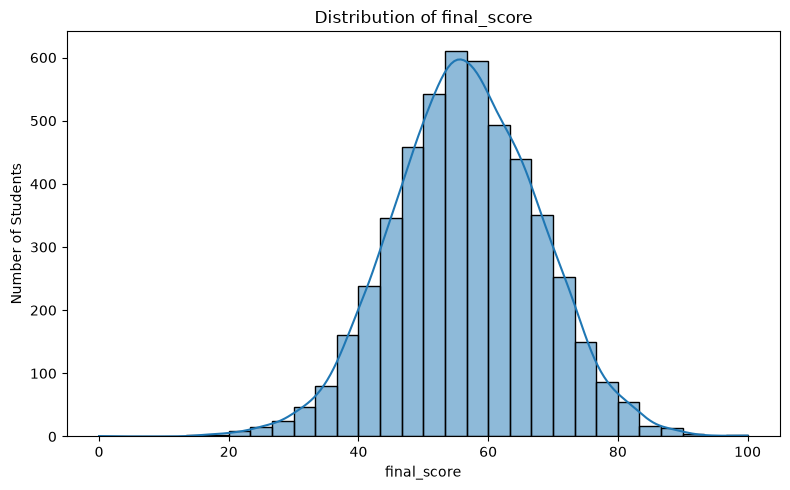

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical features
numeric_features = [
    "attendance",
    "previous_cgpa",
    "internal_marks",
    "assignment_score",
    "study_hours",
    "backlogs",
    "previous_failures",
    "participation_score",
    "final_score",
]

# Plot distributions
for feature in numeric_features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=30,
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Students")
    plt.tight_layout()
    plt.show()

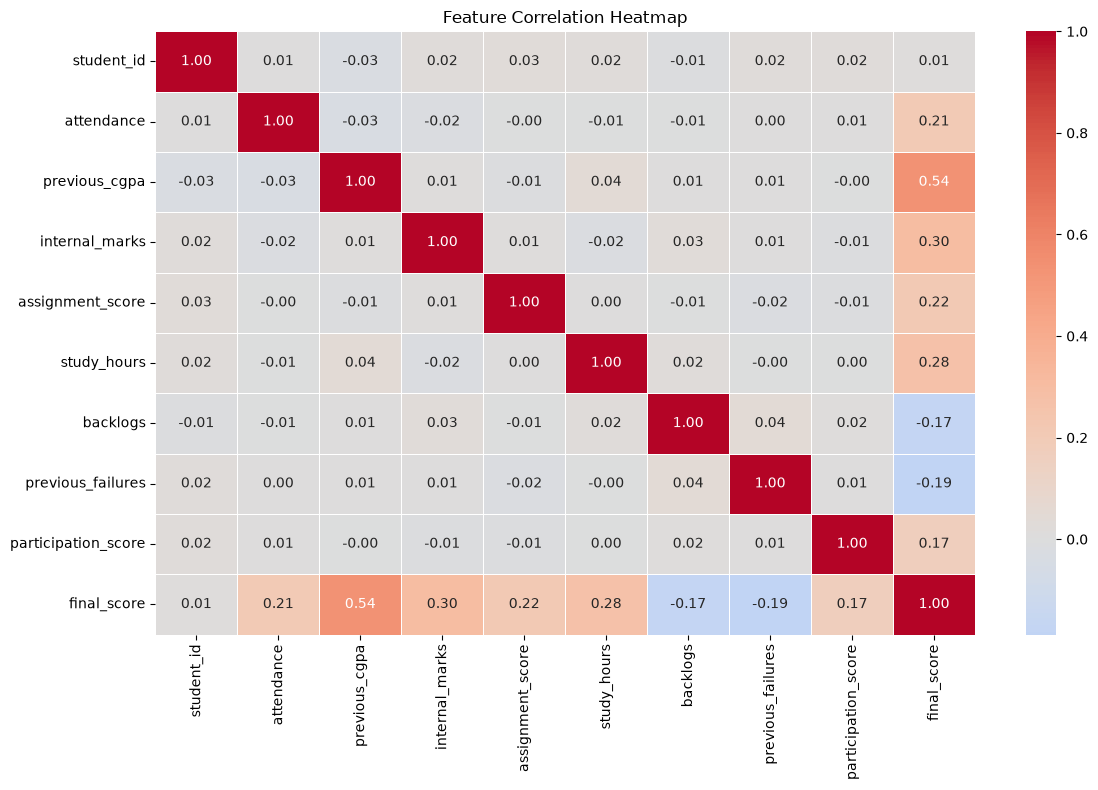

In [5]:
# Correlation Analysis

plt.figure(figsize=(12, 8))

correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
# Outlier Analysis using IQR method

numeric_features = [
    "attendance",
    "previous_cgpa",
    "internal_marks",
    "assignment_score",
    "study_hours",
    "backlogs",
    "previous_failures",
    "participation_score",
    "final_score",
]

outlier_summary = []

for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[feature] < lower_bound)
        | (df[feature] > upper_bound)
    )

    outlier_summary.append(
        {
            "feature": feature,
            "Q1": round(Q1, 2),
            "Q3": round(Q3, 2),
            "lower_bound": round(lower_bound, 2),
            "upper_bound": round(upper_bound, 2),
            "outlier_count": int(outliers.sum()),
            "outlier_percentage": round(
                outliers.mean() * 100,
                2,
            ),
        }
    )

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        "outlier_percentage",
        ascending=False,
    )
)

,feature,Q1,Q3,lower_bound,upper_bound,outlier_count,outlier_percentage
5,backlogs,0.00,1.00,-1.50,2.50,234,4.68
6,previous_failures,0.00,1.00,-1.50,2.50,85,1.70
8,final_score,49.15,64.25,26.49,86.90,49,0.98
7,participation_score,56.63,78.97,23.11,112.49,28,0.56
1,previous_cgpa,6.41,8.01,4.01,10.41,28,0.56
0,attendance,69.70,85.57,45.89,109.38,22,0.44
4,study_hours,2.35,4.71,-1.19,8.26,22,0.44
2,internal_marks,57.79,77.94,27.57,108.15,17,0.34
3,assignment_score,63.04,82.23,34.25,111.02,12,0.24


In [8]:
# ============================================================
# Risk Level Analysis
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Average academic features by risk level
risk_profile = (
    df.groupby("risk_level")[
        [
            "attendance",
            "previous_cgpa",
            "internal_marks",
            "assignment_score",
            "study_hours",
            "backlogs",
            "previous_failures",
            "participation_score",
            "final_score",
        ]
    ]
    .mean()
    .round(2)
)

print("=== AVERAGE PROFILE BY RISK LEVEL ===")
display(risk_profile)

=== AVERAGE PROFILE BY RISK LEVEL ===


,attendance,previous_cgpa,internal_marks,assignment_score,study_hours,backlogs,previous_failures,participation_score,final_score
risk_level,,,,,,,,,
HIGH,69.54,6.55,62.04,69.47,2.71,1.26,0.85,63.88,45.86
LOW,81.83,7.51,70.47,74.36,4.13,0.63,0.38,69.40,62.02
MEDIUM,75.01,7.02,66.40,71.38,3.14,0.86,0.59,66.54,53.42


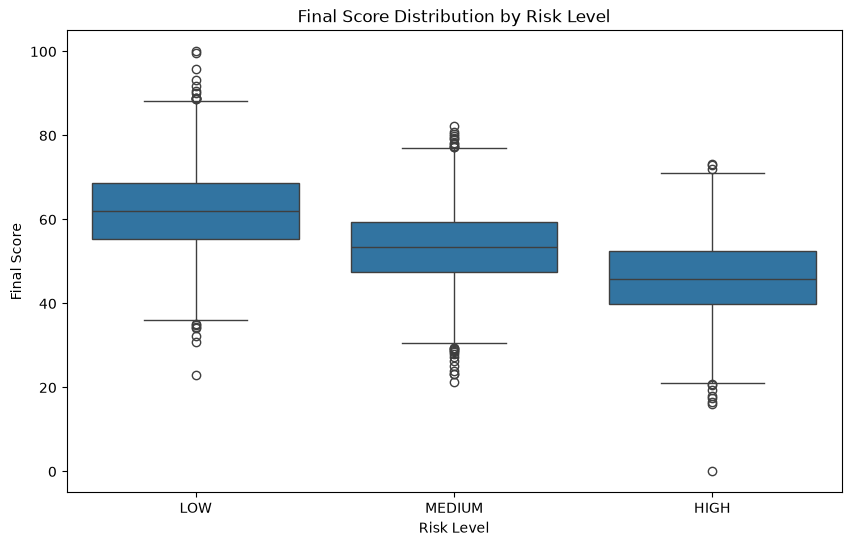

In [9]:
# Final score distribution by risk level

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="risk_level",
    y="final_score",
    order=["LOW", "MEDIUM", "HIGH"]
)

plt.title("Final Score Distribution by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Final Score")

plt.show()

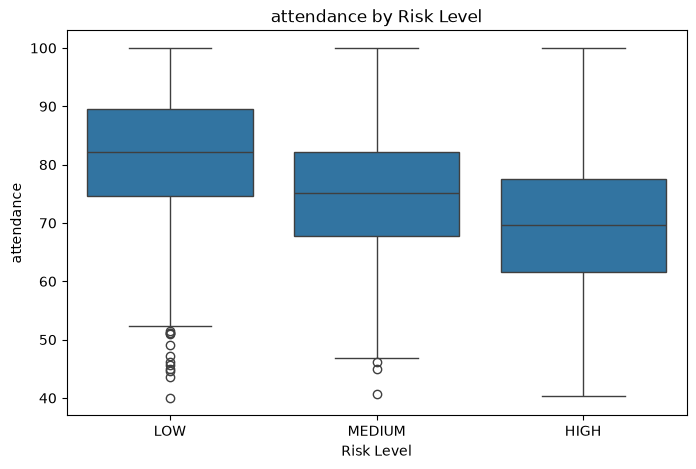

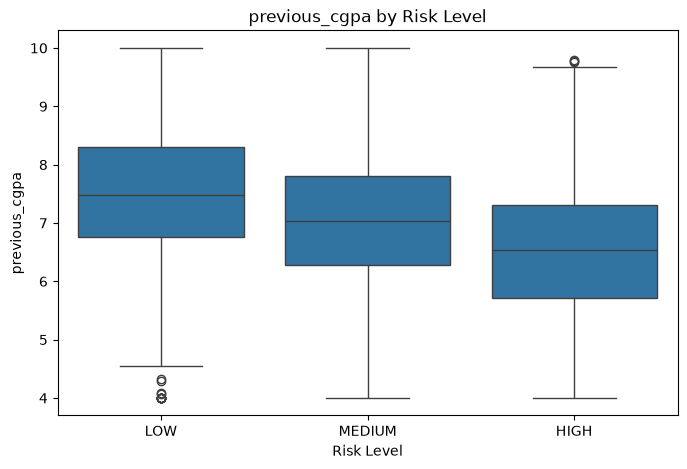

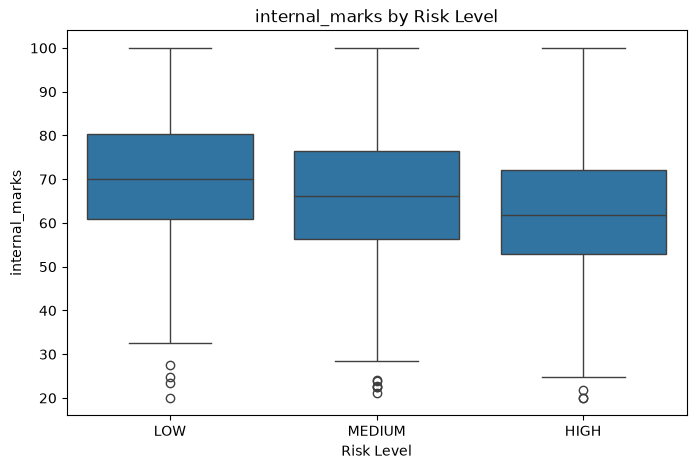

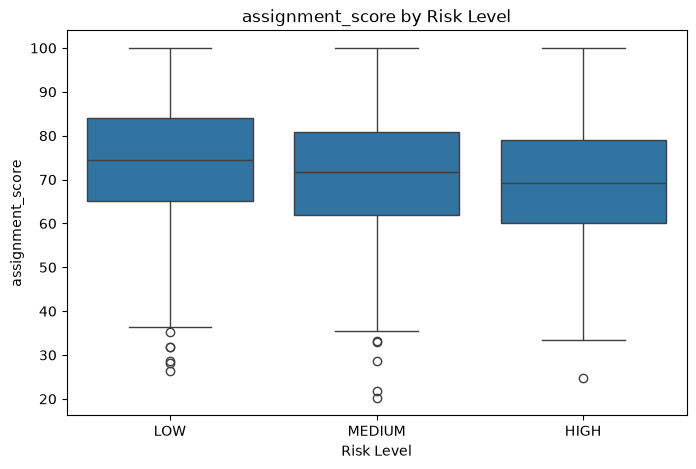

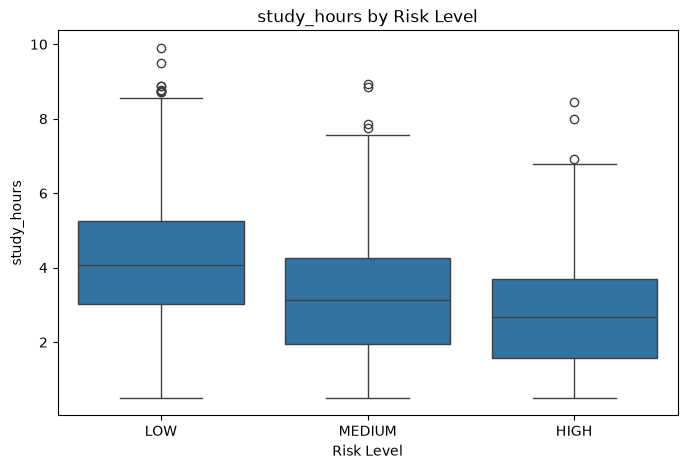

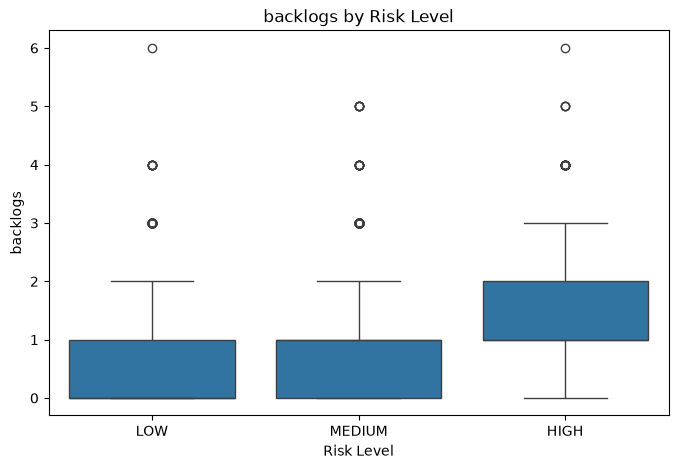

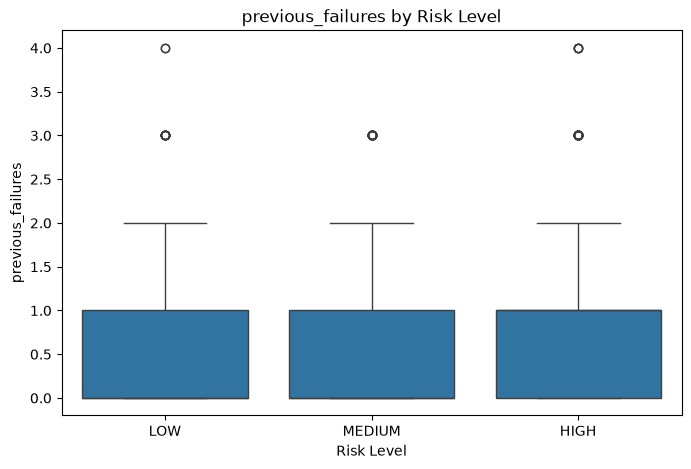

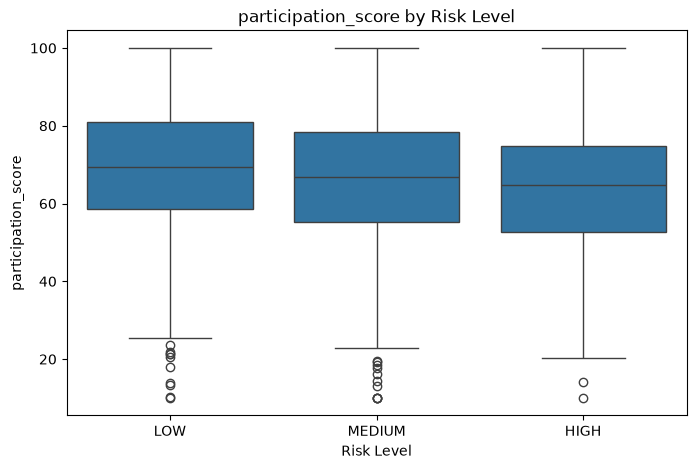

In [10]:
# Academic features by risk level

features = [
    "attendance",
    "previous_cgpa",
    "internal_marks",
    "assignment_score",
    "study_hours",
    "backlogs",
    "previous_failures",
    "participation_score",
]

for feature in features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="risk_level",
        y=feature,
        order=["LOW", "MEDIUM", "HIGH"]
    )

    plt.title(f"{feature} by Risk Level")
    plt.xlabel("Risk Level")
    plt.ylabel(feature)

    plt.show()

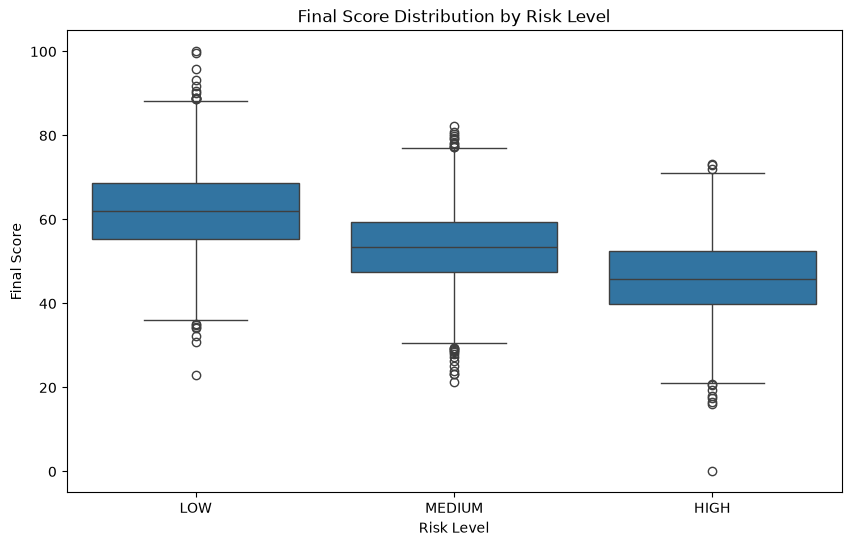

In [11]:
# ============================================================
# Risk Level vs Final Score
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="risk_level",
    y="final_score",
    order=["LOW", "MEDIUM", "HIGH"]
)

plt.title("Final Score Distribution by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Final Score")

plt.show()


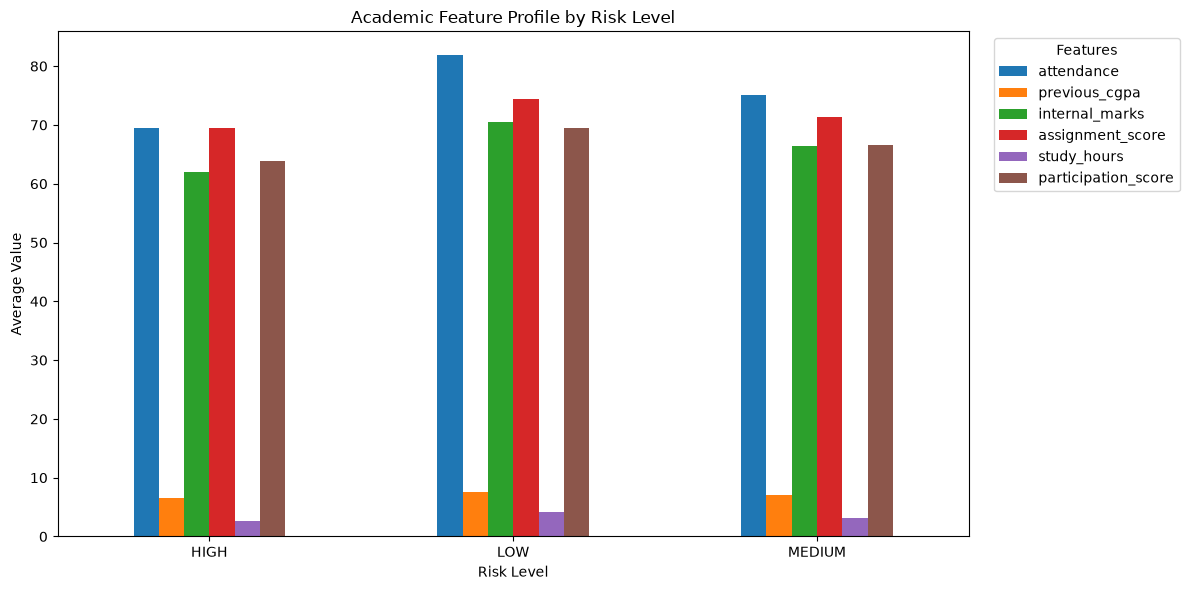

In [12]:
# ============================================================
# Average Feature Profile by Risk Level
# ============================================================

risk_profile_plot = risk_profile[
    [
        "attendance",
        "previous_cgpa",
        "internal_marks",
        "assignment_score",
        "study_hours",
        "participation_score",
    ]
]

risk_profile_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Academic Feature Profile by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Features", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()

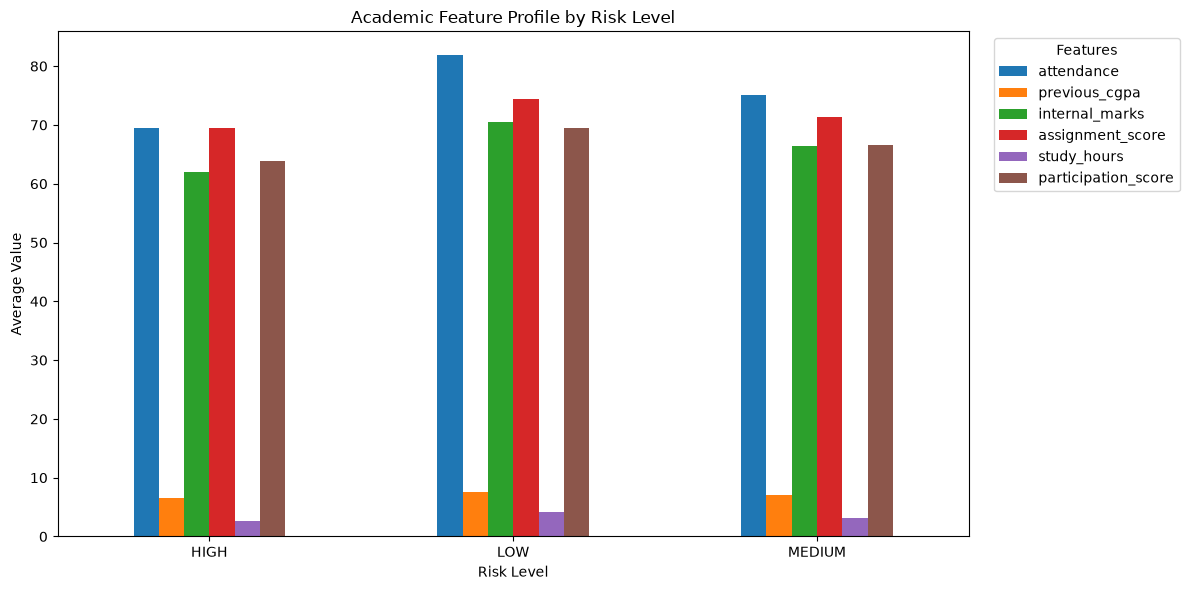

In [13]:
# ============================================================
# Average Academic Profile by Risk Level
# ============================================================

risk_profile_plot = risk_profile[
    [
        "attendance",
        "previous_cgpa",
        "internal_marks",
        "assignment_score",
        "study_hours",
        "participation_score",
    ]
]

risk_profile_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Academic Feature Profile by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(
    title="Features",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# ML PREPARATION - FEATURE / TARGET SEPARATION
# ============================================================

# student_id model ke liye useful predictive feature nahi hai
# risk_level ko abhi classification target ke liye separately rakhenge

feature_columns = [
    "attendance",
    "previous_cgpa",
    "internal_marks",
    "assignment_score",
    "study_hours",
    "backlogs",
    "previous_failures",
    "participation_score",
]

X = df[feature_columns]

y_regression = df["final_score"]
y_classification = df["risk_level"]

print("=== FEATURES ===")
print(X.columns.tolist())

print("\nFeature shape:", X.shape)
print("Regression target shape:", y_regression.shape)
print("Classification target shape:", y_classification.shape)

print("\n=== CLASSIFICATION TARGET ===")
print(y_classification.value_counts())


=== FEATURES ===
['attendance', 'previous_cgpa', 'internal_marks', 'assignment_score', 'study_hours', 'backlogs', 'previous_failures', 'participation_score']

Feature shape: (5000, 8)
Regression target shape: (5000,)
Classification target shape: (5000,)

=== CLASSIFICATION TARGET ===
risk_level
LOW       2500
MEDIUM    1750
HIGH       750
Name: count, dtype: int64


In [15]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Regression split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_regression,
    test_size=0.20,
    random_state=42
)

# Classification split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("=== REGRESSION ===")
print("Training samples:", X_train_reg.shape[0])
print("Testing samples :", X_test_reg.shape[0])

print("\n=== CLASSIFICATION ===")
print("Training samples:", X_train_cls.shape[0])
print("Testing samples :", X_test_cls.shape[0])

print("\n=== CLASS DISTRIBUTION IN TRAINING DATA ===")
print(y_train_cls.value_counts())

print("\n=== CLASS DISTRIBUTION IN TESTING DATA ===")
print(y_test_cls.value_counts())

=== REGRESSION ===
Training samples: 4000
Testing samples : 1000

=== CLASSIFICATION ===
Training samples: 4000
Testing samples : 1000

=== CLASS DISTRIBUTION IN TRAINING DATA ===
risk_level
LOW       2000
MEDIUM    1400
HIGH       600
Name: count, dtype: int64

=== CLASS DISTRIBUTION IN TESTING DATA ===
risk_level
LOW       500
MEDIUM    350
HIGH      150
Name: count, dtype: int64


In [16]:
# ============================================================
# FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

# Separate scalers for regression and classification
scaler_reg = StandardScaler()
scaler_cls = StandardScaler()

# Fit ONLY on training data
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

X_train_cls_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_cls_scaled = scaler_cls.transform(X_test_cls)

print("=== SCALING COMPLETE ===")

print("Regression training shape:", X_train_reg_scaled.shape)
print("Regression testing shape :", X_test_reg_scaled.shape)

print("Classification training shape:", X_train_cls_scaled.shape)
print("Classification testing shape :", X_test_cls_scaled.shape)

print("\n=== FIRST TRAINING SAMPLE AFTER SCALING ===")
print(X_train_reg_scaled[0])

=== SCALING COMPLETE ===
Regression training shape: (4000, 8)
Regression testing shape : (1000, 8)
Classification training shape: (4000, 8)
Classification testing shape : (1000, 8)

=== FIRST TRAINING SAMPLE AFTER SCALING ===
[ 1.92998719 -0.81788903  1.32314986  1.44752661 -0.00508847  1.33020501
 -0.72919841 -2.33915938]


In [17]:
# ============================================================
# BASELINE REGRESSION MODEL
# Linear Regression
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Create model
linear_model = LinearRegression()

# Train
linear_model.fit(
    X_train_reg_scaled,
    y_train_reg
)

# Predict
y_pred_linear = linear_model.predict(
    X_test_reg_scaled
)

# Evaluation
mae = mean_absolute_error(
    y_test_reg,
    y_pred_linear
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_linear
    )
)

r2 = r2_score(
    y_test_reg,
    y_pred_linear
)

print("========================================")
print("LINEAR REGRESSION RESULTS")
print("========================================")

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

LINEAR REGRESSION RESULTS
MAE  : 5.3968
RMSE : 6.7462
R²   : 0.6507


In [18]:
# ============================================================
# RANDOM FOREST REGRESSION
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(
    X_train_reg,
    y_train_reg
)

# Predict
y_pred_rf = rf_model.predict(
    X_test_reg
)

# Evaluation
rf_mae = mean_absolute_error(
    y_test_reg,
    y_pred_rf
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_rf
    )
)

rf_r2 = r2_score(
    y_test_reg,
    y_pred_rf
)

print("========================================")
print("RANDOM FOREST REGRESSION RESULTS")
print("========================================")

print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

RANDOM FOREST REGRESSION RESULTS
MAE  : 5.8142
RMSE : 7.2794
R²   : 0.5933


In [19]:
# ============================================================
# GRADIENT BOOSTING REGRESSION
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train
gb_model.fit(
    X_train_reg,
    y_train_reg
)

# Predict
y_pred_gb = gb_model.predict(
    X_test_reg
)

# Evaluation
gb_mae = mean_absolute_error(
    y_test_reg,
    y_pred_gb
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_gb
    )
)

gb_r2 = r2_score(
    y_test_reg,
    y_pred_gb
)

print("========================================")
print("GRADIENT BOOSTING REGRESSION RESULTS")
print("========================================")

print(f"MAE  : {gb_mae:.4f}")
print(f"RMSE : {gb_rmse:.4f}")
print(f"R²   : {gb_r2:.4f}")

GRADIENT BOOSTING REGRESSION RESULTS
MAE  : 5.5394
RMSE : 6.9302
R²   : 0.6314


In [20]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

xgb_model.fit(X_train_reg, y_train_reg)

y_pred_xgb = xgb_model.predict(X_test_reg)

xgb_mae = mean_absolute_error(y_test_reg, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb))
xgb_r2 = r2_score(y_test_reg, y_pred_xgb)

print("========================================")
print("XGBOOST REGRESSION RESULTS")
print("========================================")
print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"R²   : {xgb_r2:.4f}")

XGBOOST REGRESSION RESULTS
MAE  : 5.5167
RMSE : 6.9031
R²   : 0.6343


In [21]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_cls_scaled, y_train_cls)

y_pred_logistic = logistic_model.predict(X_test_cls_scaled)

accuracy = accuracy_score(y_test_cls, y_pred_logistic)

print("========================================")
print("LOGISTIC REGRESSION CLASSIFICATION")
print("========================================")
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_logistic))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred_logistic))


LOGISTIC REGRESSION CLASSIFICATION
Accuracy: 0.7300

Classification Report:
              precision    recall  f1-score   support

        HIGH       0.80      0.51      0.63       150
         LOW       0.80      0.85      0.82       500
      MEDIUM       0.61      0.65      0.63       350

    accuracy                           0.73      1000
   macro avg       0.74      0.67      0.69      1000
weighted avg       0.73      0.73      0.73      1000


Confusion Matrix:
[[ 77   3  70]
 [  1 425  74]
 [ 18 104 228]]


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_classifier.fit(X_train_cls, y_train_cls)

y_pred_rf_cls = rf_classifier.predict(X_test_cls)

rf_cls_accuracy = accuracy_score(y_test_cls, y_pred_rf_cls)

print("========================================")
print("RANDOM FOREST CLASSIFICATION")
print("========================================")
print(f"Accuracy: {rf_cls_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_rf_cls))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred_rf_cls))

RANDOM FOREST CLASSIFICATION
Accuracy: 0.6820

Classification Report:
              precision    recall  f1-score   support

        HIGH       0.61      0.55      0.58       150
         LOW       0.79      0.79      0.79       500
      MEDIUM       0.56      0.59      0.57       350

    accuracy                           0.68      1000
   macro avg       0.66      0.64      0.65      1000
weighted avg       0.68      0.68      0.68      1000


Confusion Matrix:
[[ 83   8  59]
 [  4 393 103]
 [ 48  96 206]]


In [23]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert class labels to numeric values
class_mapping = {
    "HIGH": 0,
    "LOW": 1,
    "MEDIUM": 2
}

y_train_cls_encoded = y_train_cls.map(class_mapping)
y_test_cls_encoded = y_test_cls.map(class_mapping)

xgb_classifier = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss"
)

xgb_classifier.fit(X_train_cls, y_train_cls_encoded)

y_pred_xgb_cls_encoded = xgb_classifier.predict(X_test_cls)

reverse_mapping = {
    0: "HIGH",
    1: "LOW",
    2: "MEDIUM"
}

y_pred_xgb_cls = pd.Series(y_pred_xgb_cls_encoded).map(reverse_mapping)

xgb_cls_accuracy = accuracy_score(y_test_cls, y_pred_xgb_cls)

print("========================================")
print("XGBOOST CLASSIFICATION")
print("========================================")
print(f"Accuracy: {xgb_cls_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_xgb_cls))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred_xgb_cls))

XGBOOST CLASSIFICATION
Accuracy: 0.7010

Classification Report:
              precision    recall  f1-score   support

        HIGH       0.69      0.41      0.51       150
         LOW       0.78      0.85      0.82       500
      MEDIUM       0.58      0.61      0.60       350

    accuracy                           0.70      1000
   macro avg       0.68      0.62      0.64      1000
weighted avg       0.70      0.70      0.69      1000


Confusion Matrix:
[[ 61   6  83]
 [  3 426  71]
 [ 25 111 214]]


In [24]:
import shap
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.LinearExplainer(
    logistic_model,
    X_train_cls_scaled
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_cls_scaled)

print("SHAP analysis completed successfully!")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP analysis completed successfully!
SHAP values shape: (1000, 8, 3)



===== HIGH RISK =====
               feature  mean_abs_shap
0           attendance       1.047939
4          study_hours       0.842177
1        previous_cgpa       0.840058
2       internal_marks       0.630126
5             backlogs       0.622442
6    previous_failures       0.621578
3     assignment_score       0.356027
7  participation_score       0.335049


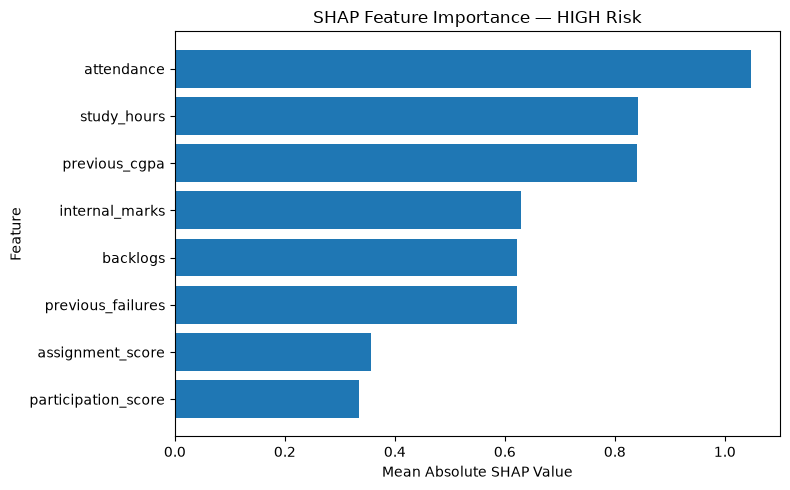


===== LOW RISK =====
               feature  mean_abs_shap
0           attendance       1.093736
4          study_hours       0.904742
1        previous_cgpa       0.840933
6    previous_failures       0.646784
5             backlogs       0.612382
2       internal_marks       0.599828
3     assignment_score       0.369329
7  participation_score       0.335994


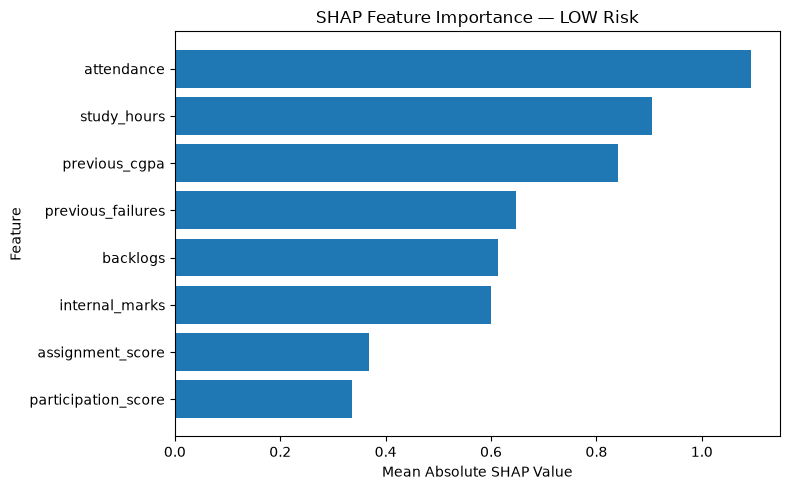


===== MEDIUM RISK =====
               feature  mean_abs_shap
4          study_hours       0.062566
0           attendance       0.045797
2       internal_marks       0.030298
6    previous_failures       0.025206
3     assignment_score       0.013303
5             backlogs       0.010060
7  participation_score       0.000946
1        previous_cgpa       0.000875


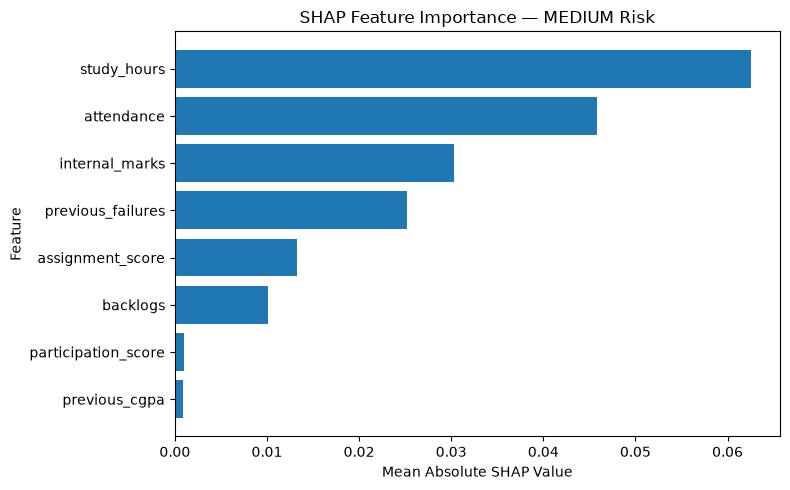

In [25]:
# SHAP feature importance for each risk class

class_names = logistic_model.classes_

for class_index, class_name in enumerate(class_names):
    print(f"\n===== {class_name} RISK =====")

    class_shap_values = shap_values[:, :, class_index]

    shap_importance = pd.DataFrame({
        "feature": feature_columns,
        "mean_abs_shap": np.abs(class_shap_values).mean(axis=0)
    }).sort_values("mean_abs_shap", ascending=False)

    print(shap_importance)

    plt.figure(figsize=(8, 5))
    plt.barh(
        shap_importance["feature"][::-1],
        shap_importance["mean_abs_shap"][::-1]
    )
    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Feature")
    plt.title(f"SHAP Feature Importance — {class_name} Risk")
    plt.tight_layout()
    plt.show()

In [26]:
# Select one student from test data
student_index = 0

student_data = X_test_cls.iloc[[student_index]]
student_scaled = X_test_cls_scaled[student_index:student_index + 1]

# Prediction
student_prediction = logistic_model.predict(student_scaled)[0]
student_probabilities = logistic_model.predict_proba(student_scaled)[0]

print("========================================")
print("INDIVIDUAL STUDENT RISK EXPLANATION")
print("========================================")
print(f"Predicted Risk: {student_prediction}")

print("\nRisk Probabilities:")
for class_name, probability in zip(
    logistic_model.classes_,
    student_probabilities
):
    print(f"{class_name}: {probability:.4f}")

# SHAP values for predicted class
predicted_class_index = list(logistic_model.classes_).index(
    student_prediction
)

student_shap = shap_values[
    student_index,
    :,
    predicted_class_index
]

explanation = pd.DataFrame({
    "feature": feature_columns,
    "value": student_data.iloc[0].values,
    "shap_value": student_shap
})

explanation["absolute_impact"] = np.abs(
    explanation["shap_value"]
)

explanation = explanation.sort_values(
    "absolute_impact",
    ascending=False
)

print("\nFeature Contributions:")
print(explanation)

INDIVIDUAL STUDENT RISK EXPLANATION
Predicted Risk: LOW

Risk Probabilities:
HIGH: 0.0009
LOW: 0.8777
MEDIUM: 0.1213

Feature Contributions:
               feature  value  shap_value  absolute_impact
1        previous_cgpa   8.86    1.459573         1.459573
0           attendance  70.99   -0.773352         0.773352
5             backlogs   0.00    0.748444         0.748444
6    previous_failures   0.00    0.636114         0.636114
7  participation_score  51.39   -0.431671         0.431671
2       internal_marks  76.11    0.414435         0.414435
4          study_hours   3.61    0.075816         0.075816
3     assignment_score  71.83   -0.003369         0.003369


In [27]:
def generate_recommendations(student):
    recommendations = []

    if student["attendance"] < 75:
        recommendations.append(
            "Improve attendance to at least 75%."
        )

    if student["previous_cgpa"] < 6.5:
        recommendations.append(
            "Focus on improving CGPA through regular revision and practice."
        )

    if student["internal_marks"] < 60:
        recommendations.append(
            "Increase internal assessment performance with targeted preparation."
        )

    if student["assignment_score"] < 60:
        recommendations.append(
            "Complete assignments regularly and improve assignment performance."
        )

    if student["study_hours"] < 3:
        recommendations.append(
            "Increase daily study time with a consistent study schedule."
        )

    if student["backlogs"] > 0:
        recommendations.append(
            "Clear pending backlogs with a prioritized study plan."
        )

    if student["previous_failures"] > 0:
        recommendations.append(
            "Focus on subjects with previous failures and seek additional support."
        )

    if student["participation_score"] < 60:
        recommendations.append(
            "Increase class participation and academic engagement."
        )

    if not recommendations:
        recommendations.append(
            "Maintain your current academic habits and performance."
        )

    return recommendations


# Generate recommendations for the selected student
student = student_data.iloc[0]

recommendations = generate_recommendations(student)

print("========================================")
print("PERSONALIZED RECOMMENDATIONS")
print("========================================")

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

PERSONALIZED RECOMMENDATIONS
1. Improve attendance to at least 75%.
2. Increase class participation and academic engagement.


In [28]:
import joblib
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save regression model
joblib.dump(
    linear_model,
    "../models/performance_regression_model.pkl"
)

# Save classification model
joblib.dump(
    logistic_model,
    "../models/risk_classification_model.pkl"
)

# Save scalers
joblib.dump(
    scaler_reg,
    "../models/regression_scaler.pkl"
)

joblib.dump(
    scaler_cls,
    "../models/classification_scaler.pkl"
)

# Save feature names
joblib.dump(
    feature_columns,
    "../models/feature_columns.pkl"
)

print("========================================")
print("MODELS SAVED SUCCESSFULLY")
print("========================================")

print("\nSaved files:")

for file in os.listdir("../models"):
    print("-", file)

MODELS SAVED SUCCESSFULLY

Saved files:
- classification_scaler.pkl
- feature_columns.pkl
- performance_regression_model.pkl
- regression_scaler.pkl
- risk_classification_model.pkl
